# Phase 2.3 — Statistical Robustness & Model Comparison

Run the first three CLI phases, followed by `python -m quant_trading.phase2_robustness`. The notebook only reads **validation-stage diagnostics** and training-era correlations. It never accesses the held-out test.

**Statistical caution:** Model selection on development validation invalidates strong confirmatory interpretations of fixed-model resampling intervals. The Moving Block Bootstrap below is *exploratory*, not a definitive hypothesis test.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd().resolve()
for PROJECT_ROOT in (current_dir, *current_dir.parents):
    if (PROJECT_ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")
REPORT_DIR = PROJECT_ROOT / "reports" / "phase2_3"
assert (REPORT_DIR / "config.json").is_file(), "Run python -m quant_trading.phase2_robustness first"
config = json.loads((REPORT_DIR / "config.json").read_text(encoding="utf-8"))
print("Bootstrap replicates:", config["bootstrap_replicates"])
print("Volatility regime cut from TRAIN Q75:", config["volatility_regime_threshold_from_train_q75"])
print("Held-out test used:", config["test_used"])

Bootstrap replicates: 2000
Volatility regime cut from TRAIN Q75: 0.179281139103811
Held-out test used: False


## 1. Pairwise losses and Moving Block Bootstrap

Define \(d_t=\ell_t^{LR}-\ell_t^{XGB}\). Positive means XGBoost has lower pointwise Log Loss. The reported interval is a 95% **percentile** Moving Block Bootstrap CI for the mean difference. Sensitivity: block lengths 5, 10 and 20 trading observations.

,comparison,block_length,n_bootstrap,mean_difference,ci_lower,ci_upper
0,lr_minus_xgboost,5,2000,0.001171,-0.003473,0.005981
1,lr_minus_xgboost,10,2000,0.001171,-0.003573,0.005904
2,lr_minus_xgboost,20,2000,0.001171,-0.003837,0.006497
3,baseline_minus_logistic,5,2000,-0.007912,-0.014685,-0.002140
4,baseline_minus_logistic,10,2000,-0.007912,-0.015875,-0.001737
5,baseline_minus_logistic,20,2000,-0.007912,-0.017216,-0.000939
6,baseline_minus_xgboost,5,2000,-0.006740,-0.012821,-0.001350
7,baseline_minus_xgboost,10,2000,-0.006740,-0.013549,-0.001185
8,baseline_minus_xgboost,20,2000,-0.006740,-0.014597,-0.000225


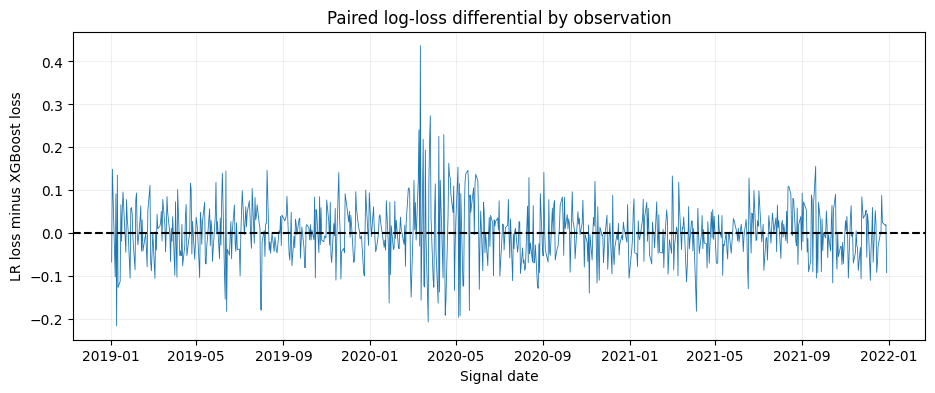

In [2]:
losses = pd.read_csv(REPORT_DIR / "paired_losses.csv",
                     parse_dates=["signal_date"]).set_index("signal_date")
bootstrap = pd.read_csv(REPORT_DIR / "block_bootstrap.csv")
display(bootstrap)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(losses.index, losses["lr_minus_xgboost"], lw=.6)
ax.axhline(0, ls="--", color="black")
ax.set(xlabel="Signal date", ylabel="LR loss minus XGBoost loss",
       title="Paired log-loss differential by observation")
ax.grid(alpha=.2)
plt.show()

## 2. Uncertainty visualization (sensitivity to block length)

A CI crossing zero indicates insufficient evidence to distinguish expected losses under the adopted assumptions; it does **not** show the models are equivalent.

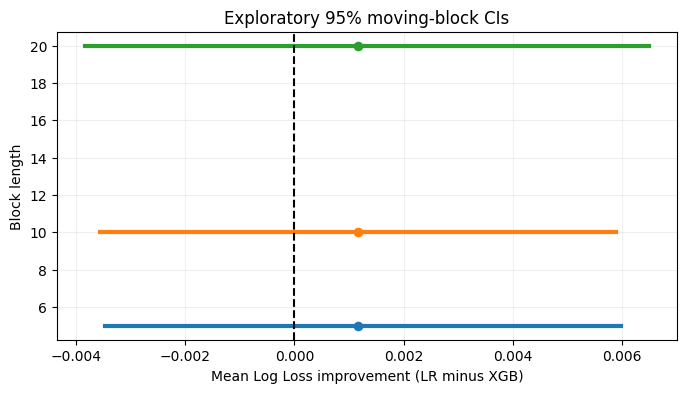

In [3]:
selected = bootstrap.query("comparison == 'lr_minus_xgboost'").sort_values("block_length")
fig, ax = plt.subplots(figsize=(8, 4))
for row in selected.itertuples():
    ax.plot([row.ci_lower, row.ci_upper], [row.block_length]*2, lw=3)
    ax.scatter([row.mean_difference], [row.block_length], s=35)
ax.axvline(0, ls="--", color="black")
ax.set(xlabel="Mean Log Loss improvement (LR minus XGB)",
       ylabel="Block length", title="Exploratory 95% moving-block CIs")
ax.grid(alpha=.2)
plt.show()

## 3. Yearly performance and 63-observation rolling Log Loss

Check whether a small total improvement is concentrated in a single market period. Rolling losses overlap: their points are not independent.

,year,model,observations,log_loss,brier_score,roc_auc,observed_positive_rate,mean_predicted_probability
0,2019,Constant Probability,252,0.679410,0.243147,0.500000,0.599206,0.544534
1,2019,Logistic Regression,252,0.679086,0.242992,0.503508,0.599206,0.542983
2,2019,XGBoost,252,0.677786,0.242348,0.551439,0.599206,0.535884
3,2020,Constant Probability,253,0.680539,0.243710,0.500000,0.592885,0.544534
4,2020,Logistic Regression,253,0.705709,0.255983,0.454304,0.592885,0.521500
5,2020,XGBoost,253,0.700797,0.253698,0.451456,0.592885,0.523972
6,2021,Constant Probability,250,0.677840,0.242364,0.500000,0.608000,0.544534
7,2021,Logistic Regression,250,0.676587,0.241751,0.507519,0.608000,0.551030
8,2021,XGBoost,250,0.679333,0.243115,0.482881,0.608000,0.550195


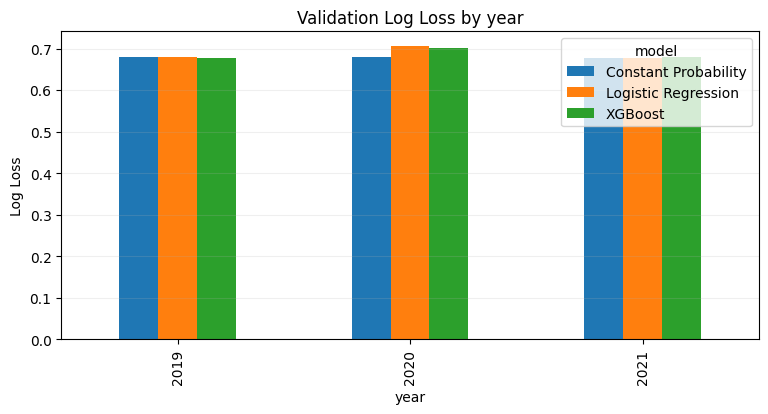

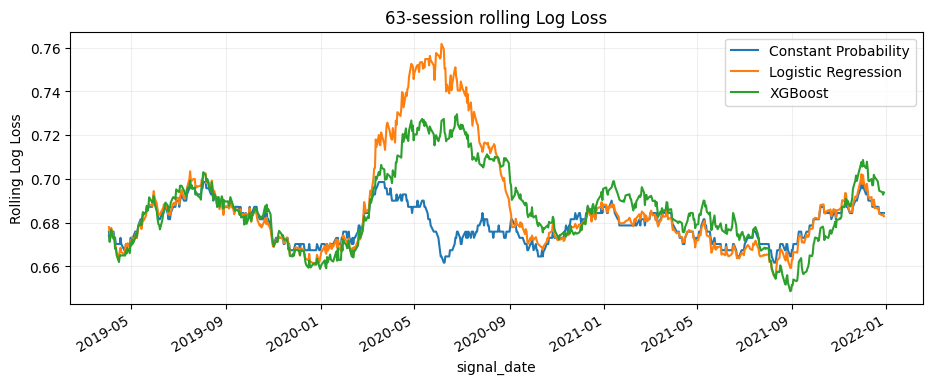

In [4]:
yearly = pd.read_csv(REPORT_DIR / "yearly_metrics.csv")
rolling = pd.read_csv(REPORT_DIR / "rolling_log_loss.csv",
                      parse_dates=["signal_date"]).set_index("signal_date")
display(yearly)
pivot = yearly.pivot(index="year", columns="model", values="log_loss")
pivot.plot.bar(figsize=(9, 4), title="Validation Log Loss by year")
plt.ylabel("Log Loss")
plt.grid(axis="y", alpha=.2)
plt.show()
rolling.plot(figsize=(11, 4), title="63-session rolling Log Loss")
plt.ylabel("Rolling Log Loss")
plt.grid(alpha=.2)
plt.show()

## 4. Volatility regime comparison

High volatility if the observed 21-day annualized volatility at signal date exceeds the training-period 75th percentile. No regime cutoffs are learned from validation labels.

,regime,model,observations,log_loss,brier_score,roc_auc,observed_positive_rate,mean_predicted_probability
0,Normal/low volatility,Constant Probability,538,0.679534,0.243209,0.500000,0.598513,0.544534
1,Normal/low volatility,Logistic Regression,538,0.679868,0.243381,0.482344,0.598513,0.549127
2,Normal/low volatility,XGBoost,538,0.682433,0.244654,0.493559,0.598513,0.544159
3,High volatility,Constant Probability,217,0.678610,0.242748,0.500000,0.603687,0.544534
4,High volatility,Logistic Regression,217,0.705310,0.255744,0.486331,0.603687,0.511974
5,High volatility,XGBoost,217,0.694875,0.250749,0.501243,0.603687,0.517969


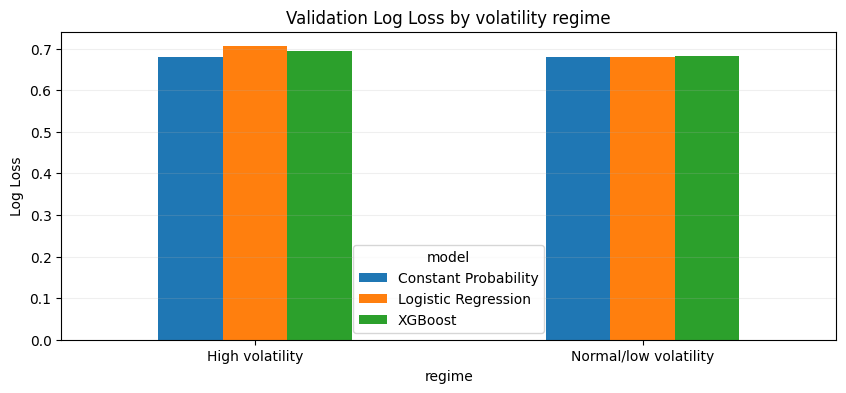

In [5]:
regimes = pd.read_csv(REPORT_DIR / "regime_metrics.csv")
display(regimes)
regimes.pivot(index="regime", columns="model", values="log_loss").plot.bar(
    figsize=(10, 4), title="Validation Log Loss by volatility regime")
plt.ylabel("Log Loss")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=.2)
plt.show()

## 5. Reliability table, training feature correlations and coefficient stability

Five quantile bins for each nonconstant model; only one bin for constant-probability baseline. Fold-specific standardized logistic coefficients are *descriptive* because expanding training windows overlap.

,model,bin,observations,mean_probability,observed_frequency
0,Constant Probability,0,755,0.544534,0.600000
1,Logistic Regression,0,151,0.477117,0.615894
2,Logistic Regression,1,151,0.532978,0.635762
3,Logistic Regression,2,151,0.545855,0.562914
4,Logistic Regression,3,151,0.556666,0.596026
5,Logistic Regression,4,151,0.579627,0.589404
6,XGBoost,0,151,0.472555,0.596026
7,XGBoost,1,151,0.521474,0.609272
8,XGBoost,2,151,0.541947,0.622517
9,XGBoost,3,151,0.560040,0.589404


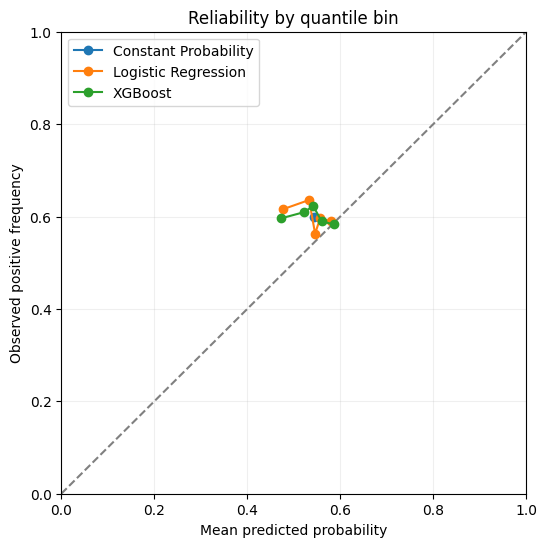

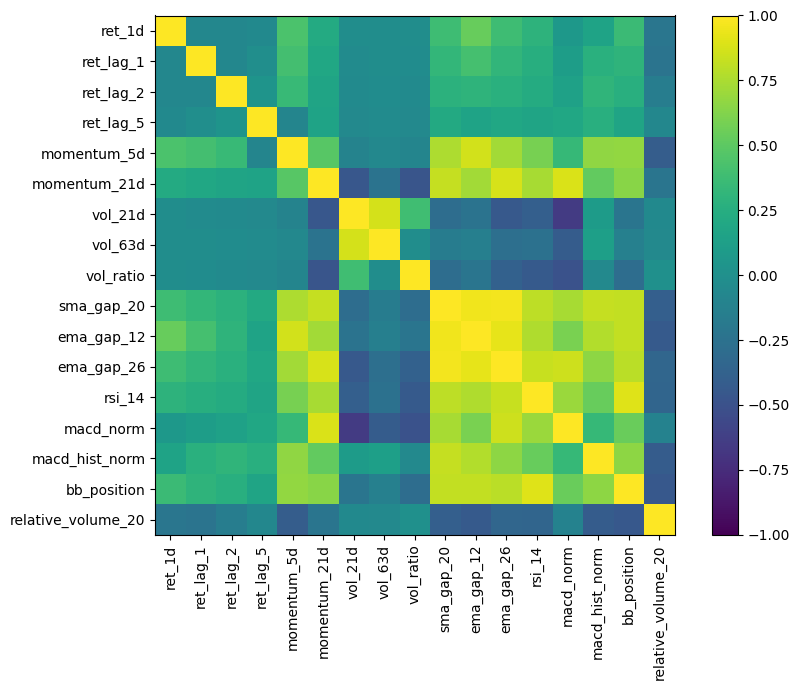

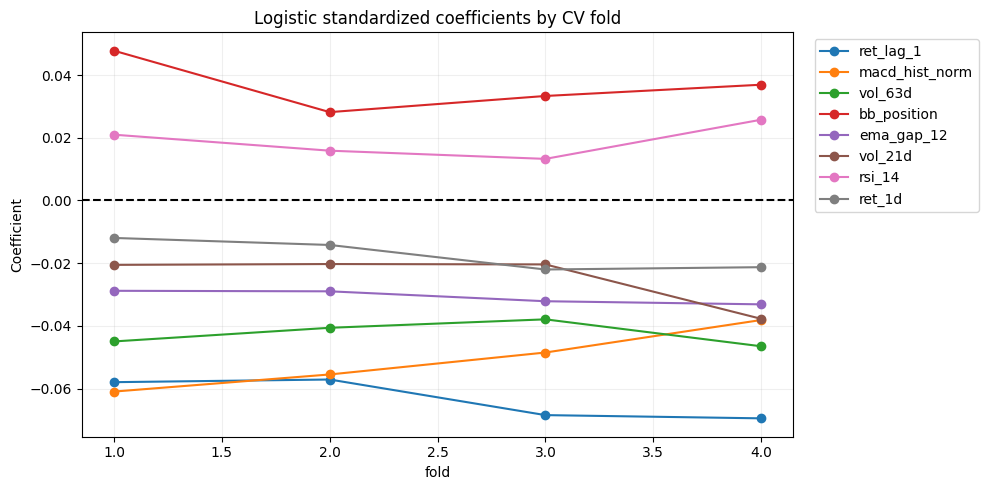

In [6]:
calibration = pd.read_csv(REPORT_DIR / "calibration_bins.csv")
coefficients = pd.read_csv(REPORT_DIR / "coefficient_stability.csv")
corr = pd.read_csv(REPORT_DIR / "train_feature_correlations.csv", index_col=0)
display(calibration)
fig, ax = plt.subplots(figsize=(6,6))
ax.plot([0,1],[0,1], '--', color='gray')
for name, part in calibration.groupby('model'):
    ax.plot(part['mean_probability'], part['observed_frequency'],
            marker='o', label=name)
ax.set(xlim=(0,1), ylim=(0,1), xlabel='Mean predicted probability',
       ylabel='Observed positive frequency', title='Reliability by quantile bin')
ax.legend(); ax.grid(alpha=.2)
plt.show()

fig, ax = plt.subplots(figsize=(9,7))
im = ax.imshow(corr, vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(corr.columns)), labels=corr.columns, rotation=90)
ax.set_yticks(np.arange(len(corr.index)), labels=corr.index)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

wide = coefficients.pivot(index='fold', columns='feature', values='coefficient_scaled')
important = wide.abs().mean().nlargest(8).index
wide[important].plot(marker='o', figsize=(10,5), title='Logistic standardized coefficients by CV fold')
plt.axhline(0, ls='--', color='black')
plt.ylabel('Coefficient')
plt.grid(alpha=.2)
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()

## How stable is the comparison?

1. **Average loss.** The prior scores 0.67927, XGBoost 0.68601 and logistic regression 0.68718. For logistic minus XGBoost, the mean paired difference is +0.00117. The exploratory 95% interval for blocks of 10 sessions is [−0.00357, +0.00590]. Blocks of 5 and 20 sessions also include zero. By contrast, prior minus either learned model is negative for all three block intervals.
2. **Years and rolling windows.** XGBoost has lower loss than logistic regression in 2019 and 2020. Logistic regression ranks ahead in 2021. In overlapping 63-session windows the logistic-minus-XGBoost difference ranges from −0.01648 to +0.03919. The sign of the advantage changes within the sample.
3. **Volatility regimes.** On the 217 high-volatility signals, XGBoost scores 0.69488 versus logistic regression’s 0.70531. On the other 538 signals, logistic regression scores 0.67987 versus XGBoost’s 0.68243. The prior has the lowest loss in both groups.
4. **Calibration.** Each nonconstant model has five groups of 151 signals. The lowest logistic group predicts 47.71% and observes 61.59% up days. The lowest XGBoost group predicts 47.26% and observes 59.60%. A single group of 755 signals suffices for the constant prior.
5. **Scope.** The bootstrap resamples contiguous blocks of fixed forecasts from one ETF and one development window. It captures some serial dependence. The uncertainty from choosing the features and models, market changes and retrospective vendor adjustments remains.